<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_14/dataset_pbl/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 2**
Pada praktikum ini kita akan membuat model CNN untuk mengklasifikasikan 10 objek dari dataset CIFAR. Dataset terdiri dari 60.000 citra dan setiap label terdiri dari 6.000 citra. Dataset telah dibagi menjadi 50.000 data training dan 10.000 data testing.
## **Langkah 1 - Load Library**


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt

## **Langkah 2 - Load & Pra Pengolahan Dataset Sleep Health**

In [ ]:
# Load dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

fitur = [
    'Age', 'Sleep Duration', 'Quality of Sleep',
    'Physical Activity Level', 'Stress Level',
    'Heart Rate', 'Daily Steps'
]
X = df[fitur].values

# Encoding target 3 kelas: None, Insomnia, Sleep Apnea
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')
le = LabelEncoder()
y = le.fit_transform(df['Sleep Disorder'])
class_names = list(le.classes_)

# Split data training (80%) dan testing (20%)
X_train_raw, X_test_raw, train_labels, test_labels = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalisasi fitur dan reshape ke format input CNN 1D: (sampel, 7 fitur, 1 channel)
scaler = StandardScaler()
train_data = scaler.fit_transform(X_train_raw).reshape((-1, 7, 1))
test_data = scaler.transform(X_test_raw).reshape((-1, 7, 1))

## **Langkah 3 - Verifikasi Data**

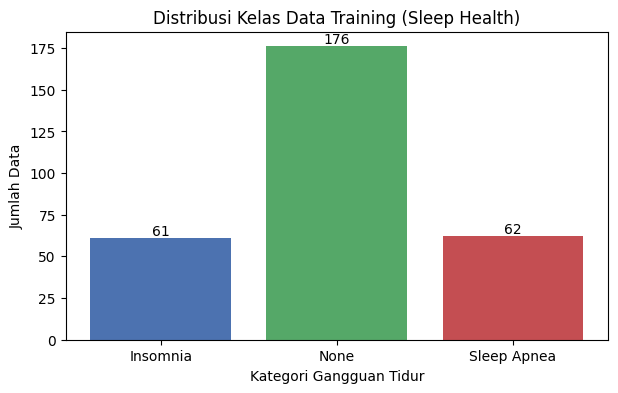

In [ ]:
counts = np.bincount(train_labels)

plt.figure(figsize=(7, 4))
bars = plt.bar(class_names, counts, color=['#4C72B0', '#55A868', '#C44E52'])
plt.title('Distribusi Kelas Data Training (Sleep Health)')
plt.xlabel('Kategori Gangguan Tidur')
plt.ylabel('Jumlah Data')
plt.bar_label(bars)
plt.show()

## **Langkah 4 - Buat Model CNN**
### **Langkah 4.1 - Buat Layer Konvolusi**


In [ ]:
model = models.Sequential()
model.add(layers.Input(shape=(7, 1)))
model.add(layers.Conv1D(32, 2, activation='relu'))
model.add(layers.MaxPooling1D(2))
model.add(layers.Conv1D(64, 2, activation='relu'))

### **Langkah 4.2 - Cek Arsitektur Konvolusi**


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 6, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2, 64)          │         4,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,256 (16.62 KB)

 Trainable params: 4,256 (16.62 KB)

 Non-trainable params: 0 (0.00 B)

### **Langkah 4.3 - Tambahkan Layer Fully Connected**


In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(3))

### **Langkah 4.4 - Cek Arsitektur Model CNN**


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 6, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2, 64)          │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,707 (49.64 KB)

 Trainable params: 12,707 (49.64 KB)

 Non-trainable params: 0 (0.00 B)

### **Langkah 4.5 - Compile Model CNN**


In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

## **Langkah 5 - Fit Model**


In [ ]:
history = model.fit(
    train_data, train_labels,
    epochs=30,
    batch_size=16,
    validation_data=(test_data, test_labels)
)

Epoch 1/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.5084 - loss: 1.0176 - val_accuracy: 0.5733 - val_loss: 0.9237
Epoch 2/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6421 - loss: 0.8365 - val_accuracy: 0.6267 - val_loss: 0.7809
Epoch 3/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7324 - loss: 0.6844 - val_accuracy: 0.7467 - val_loss: 0.6594
Epoch 4/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8094 - loss: 0.5619 - val_accuracy: 0.8667 - val_loss: 0.5479
Epoch 5/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8729 - loss: 0.4918 - val_accuracy: 0.8667 - val_loss: 0.4962
Epoch 6/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8796 - loss: 0.4506 - val_accuracy: 0.8667 - val_loss: 0.4758
Epoch 7/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8930 - loss: 0.4241 - val_accuracy: 0.8800 - val_loss: 0.4507
Epoch 8/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8729 - loss: 0.3938 - val_accuracy: 0.8800 - val_l

## **Langkah 6 - Evaluasi Model**


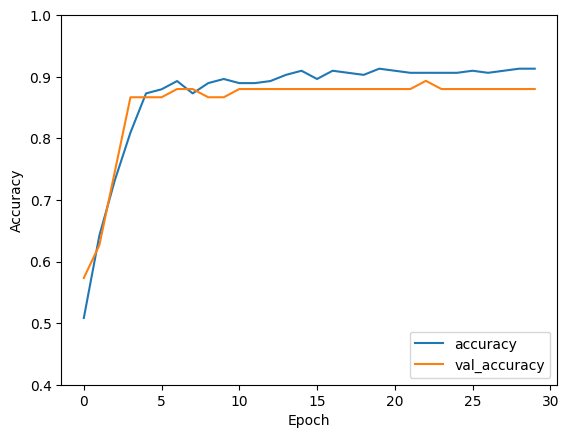

3/3 - 0s - 23ms/step - accuracy: 0.8800 - loss: 0.4589


In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.4, 1.0])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_data, test_labels, verbose=2)

## **Langkah 7 - Cetak Hasil Akurasi**

In [ ]:
print(f"Akurasi Data Testing: {test_acc * 100:.2f}%")

Akurasi Data Testing: 88.00%
